# **0. Introduction**
The goal of this project is to carry out a **clustering task** on the wholesale-customers dataset (OpenML ID: 1511) to find groups of customers with similar spending behaviour (customer segmentation).

The dataset refers to clients of a wholesale distributor. It includes the annual spending (in monetary units) on diverse product categories.

The sample size is **440**, each row is a sample (customer) and each of the 8 columns is an attribute, specifically:
- **6 numerical attributes**: they represent the annual spending on diverse product categories (*Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicassen*).
- **2 categorical attributes**: they represent customer's channel (*Channel*) and customer's region (*Region*) and have been mapped, respectively, to {1,2} and to {1,2,3}, such that:
  - for *Channel* : 1 = Hotel/Restaurant/Café ; 2 = Retail
  - for *Region* : 1 = Lisbon ; 2 = Porto ; 3 = Other

Being clustering an unsupervised learning task, the categorical attributes **will not be used** in the analysis itself, but only at the end to compute external metrics for the evaluation of clustering performances.

Different clustering techniques will be used in this analysis, specifically: **K-Means**, **Agglomerative Clustering**, **DBSCAN**.


# **1. Import Libraries & Data Loading**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc

from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    pairwise_distances,
)


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
path = "/content/drive/MyDrive/wholesale.csv"
data = pd.read_csv(path)

# **2. Preliminaries**

**2.1** **Descriptive**.

In [4]:
data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [5]:
data.describe(include="all")

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


Numerical features have **very different ranges**, appropriate normalization should be considered in the preprocessing step.

**2.2** Check if there are **missing values**.

In [6]:
data.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


There are no missing values.

**2.3** Take **only numerical** features.

In [7]:
numerical_features = ["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicassen"]
X = data[numerical_features].copy()

**2.4** Check **correlation** among numerical features.

In [8]:
X.corr(numeric_only=True).style.background_gradient("RdBu")

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000000,0.100510,-0.011854,0.345881,-0.101953,0.244690
Milk,0.100510,1.000000,0.728335,0.123994,0.661816,0.406368
Grocery,-0.011854,0.728335,1.000000,-0.040193,0.924641,0.205497
Frozen,0.345881,0.123994,-0.040193,1.000000,-0.131525,0.390947
Detergents_Paper,-0.101953,0.661816,0.924641,-0.131525,1.000000,0.069291
Delicassen,0.244690,0.406368,0.205497,0.390947,0.069291,1.000000


Grocery and Detergent_papers are the most correlated features (+0.925), followed by Groceries and Milk (+0.728).

**2.5** Check **Outliers**.

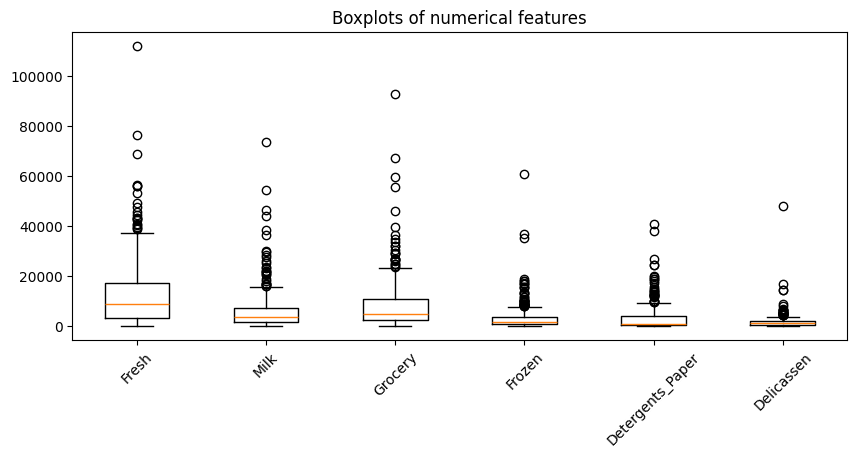

In [9]:
plt.figure(figsize=(10,4))
plt.boxplot(X, tick_labels=numerical_features)
plt.xticks(rotation=45)
plt.title("Boxplots of numerical features")
plt.show()

Every numerical feature has several **outliers** (big-spending customers) and show **strong right-skewness**.\
Outliers will be kept, but to mitigate their impact on distance-based clustering techniques, log-transformation and standardization will be applied at the preprocessing step.

# **3. Preprocessing**

**3.1 Log-transformation**

In [10]:
X_log = np.log1p(X)

Applies a log(1+x) transformation to reduce skewness and the impact of outliers on distance-based clustering algorithms.

**3.2 Standardization**

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

Applies StandardScaler to standardize every feature, i.e. to make them zero-mean and unit-variance. \
This is very important because distance-based clustering algorithms are sensitive to differing feature scales.

# **4 Visualization & Helper Functions**

**4.1 Principal Component Analysis (PCA)**

X_scaled has 6 dimensions (the number of numerical features) and the same applies to the clusters extraced from it.\
In order to visualize the resulting clusters we have to **reduce the dimensionality**, specifically to 2 dimensions. To do so, we apply PCA (only for plotting, not for clustering).

Explained variance of the first 2 components: [0.44077752 0.27194917]
Total variance explained by the first 2 components: 71.3%


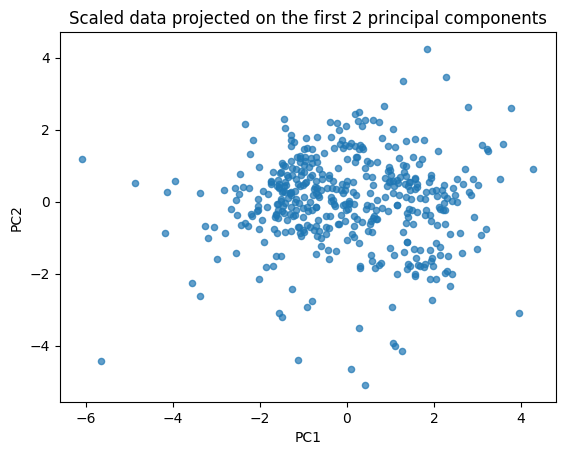

In [12]:
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance of the first 2 components:", pca.explained_variance_ratio_)
print("Total variance explained by the first 2 components: {:.1f}%".format(pca.explained_variance_ratio_.sum() * 100))

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=20, alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Scaled data projected on the first 2 principal components")
plt.show()

The first 2 components explain 71.3% of the total variability of the data, which is a farly large percetage of the total variability even though we lose 28.7% of information about total variability.\
Nevertheless, from the above plot, it is not possible to spot meaningful clearly separated groups.

**4.2 Helper functions**

In [13]:
# Plot predictions of model clf over a 2D-mesh (as countours, i.e. regions)
def plot_predictions(clf, axes, confidence=True):
    # Create a mesh grid
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s)
    # Compute predictions for mesh points
    X_ = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X_).reshape(x0.shape)
    # Plot predictions
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)
    # Plot confidence scores for samples
    if confidence:
        y_decision = clf.decision_function(X_).reshape(x0.shape)
        plt.contourf(x0, x1, y_decision, cmap=plt.cm.brg, alpha=0.1)
    return

# Helper function to plot data with features X and label y
def plot_dataset_(X, y, axes, x1_index=0, x2_index=1, labels=[]):
    # Plot each unique value in y with a different style
    for item, style in zip(set(y), ["bs", "g+", "yo", "rv", "c<", "m<"]):
        plt.plot(X[:, x1_index][y==item], X[:, x2_index][y==item], style)
    # Set axes if available
    if axes != []:
        plt.axis(axes)
    plt.grid(True, which='both')
    # Add axes labels
    if labels != []:
        plt.xlabel(labels[x1_index], fontsize=12)
        plt.ylabel(labels[x2_index], fontsize=12)
    else:
        plt.xlabel(r"$x_1$", fontsize=12)
        plt.ylabel(r"$x_2$", fontsize=12, rotation=0)
    return

# Wrapper to plot a dataset
def plot_dataset(X, y, title, x1_index=0, x2_index=1, labels=[]):
    plot_dataset_(X, y, [], x1_index=x1_index, x2_index=x2_index, labels=labels)
    plt.title(title)
    plt.show()
    return

# Wrapper to plot k-means results
def plot_kmeans_results(clf, X, y, title="", axes=[]):
    # Compute axes to use (i.e., plot axis ranges)
    if axes == []:
        for i in [0,1]:
            min_x = min(X[:,i])
            max_x = max(X[:,i])
            delta_x = (max_x-min_x)/20
            axes += [min_x-delta_x, max_x+delta_x]
    # Plot the model predictions as colored regions
    plot_predictions(clf, axes, confidence=False)
    # Plot data on top
    plot_dataset_(X, y, axes)
    # Plot centroids if available
    try:
        centroids_x = [x[0] for x in clf.cluster_centers_]
        centroids_y = [x[1] for x in clf.cluster_centers_]
        plt.plot(centroids_x, centroids_y, "k+", mew=3, ms=12)
    except:
        pass
    # Add title and show plot
    plt.title(title)
    plt.show()
    return

# **5. Choice of K** for K-Means

K-Means requires the number of clusters K as a pre-specified hyperparameter.\
There are two graphical ways that allow to *estimate* the optimal number of clusters K for a given dataset:
- The **elbow method**
- The **silhouette coefficient**

**5.1 Helper functions**



In [14]:
###### ELBOW METHOD

def get_SSE(data, clustering_algorithm, max_clusters=15):
    SSE = []
    # Calculate SSE for each number of clusters, from k=2 to k=max_clusters-1
    for k in range(2, max_clusters):
        # set the clustering algorithm
        model = clustering_algorithm(n_clusters=k, random_state=0, n_init=10)
        # train and predict from data
        model.fit_predict(data)
        # add SSE to the list of SSEs
        SSE.append(model.inertia_)
    return SSE

# Plot SSE vs the number of clusters k
def plot_SSE(data, clustering_algorithm, title="", max_clusters=15):
    SSE = get_SSE(data, clustering_algorithm, max_clusters=max_clusters)
    plt.figure()
    plt.plot(range(2, max_clusters), SSE, 'bo-')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Sum of squared distances to centroid (Inertia / SSE)')
    plt.title(title)
    plt.grid(True)
    plt.show()
    return

###### SILHOUETTE COEFFICIENTS METHOD

def get_silhouette_score(data, clustering_algorithm, max_clusters=15):
    silhouette_coefficients = []
    # Calculate silhouette score for each number of clusters, from k=2 to k=max_clusters-1
    for k in range(2, max_clusters):
        # set the clustering algorithm
        model = clustering_algorithm(n_clusters=k, random_state=0, n_init=10)
        # train and predict from data
        model.fit_predict(data)
        # calculate silhouette score for the current number of clusters
        score = silhouette_score(data, model.labels_)
        # add silhouette score to the list
        silhouette_coefficients.append(score)
    return silhouette_coefficients

# Plot silhouette score vs the number of clusters k
def plot_silhouette_score(data, clustering_algorithm, title="", max_clusters=15):
    sil_scores = get_silhouette_score(data, clustering_algorithm, max_clusters=max_clusters)
    plt.figure()
    plt.plot(range(2, max_clusters), sil_scores, 'bo-')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Silhouette coefficient')
    plt.title(title)
    plt.grid(True)
    plt.show()
    return

**5.2** **Elbow method**

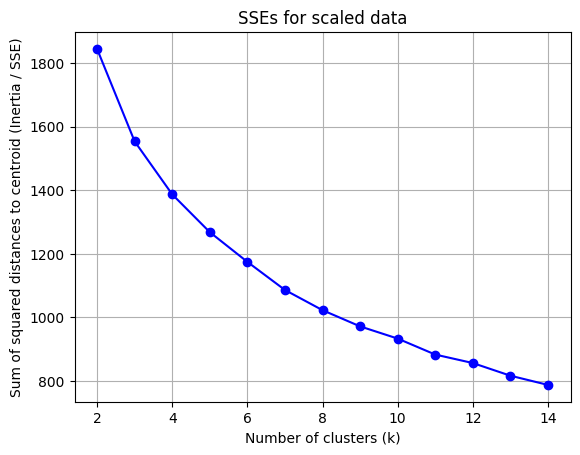

In [15]:
plot_SSE(X_scaled, KMeans, title="SSEs for scaled data")

**5.3** **Silhouette Coefficients**

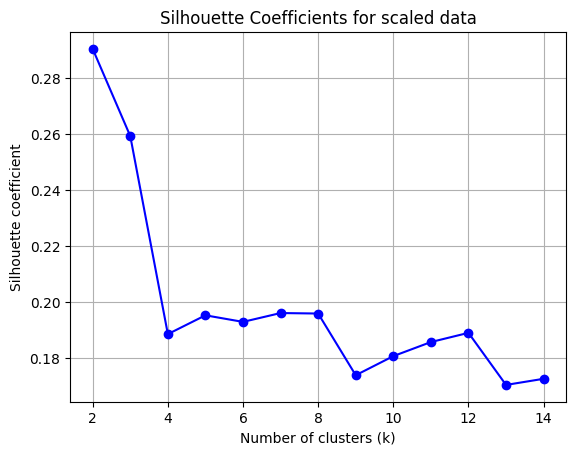

In [16]:
plot_silhouette_score(X_scaled, KMeans, title="Silhouette Coefficients for scaled data")

**5.4 Choosing K**

From the first plot it is clear that the SSE decreases as K increases, however, the decrease in SSE becomes less meaningful after the first values of K, the elbow is between K=2 and K=4 and suggesting that a sound choice could be K=3.\
From the second plot, it is clear that the silhouette coefficient is maximized for K=2, decreasing for K=3 and dropping significantly for K=4.\
Since the silhouette coefficient provides a clearer metric for cluster validity, we choose **K=2**.

## **6. K-Means**

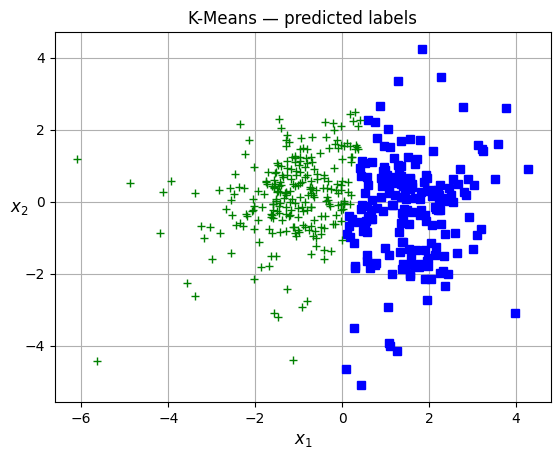


Centroid of each cluster:
 [[-0.2961649   0.80912324  0.85996674 -0.34512277  0.88510115  0.20076309]
 [ 0.22094842 -0.60363163 -0.64156249  0.25747254 -0.66031356 -0.14977564]]
SSE:  1844.0640687542127
N. iterations:  15

Cluster sizes:
0    188
1    252
Name: count, dtype: int64


In [17]:
# set clustering algorithm
clustering = KMeans(n_clusters=2)

# train and predict from data
labels_kmeans = clustering.fit_predict(X_scaled)


# plot predicted labels in the PCA-space (2-dimesional)
plot_dataset(X_pca, labels_kmeans,
             title="K-Means — predicted labels")

# print centroids and other information
print("\nCentroid of each cluster:\n", clustering.cluster_centers_)
print("SSE: ", clustering.inertia_)
print("N. iterations: ", clustering.n_iter_)
print("\nCluster sizes:")
print(pd.Series(labels_kmeans).value_counts().sort_index())

# **7. Choice of K** for Agglomerative Clustering

The function sklearn.cluster.AgglomerativeClustering() requires the number of clusters K.\
To find the best K for the dataset, the silhouette coefficients are evaluated for different types of linkage, specifically for:
- **MIN** or single link
- **MAX** or complete link
- **Group Average**
- **Ward's Method**

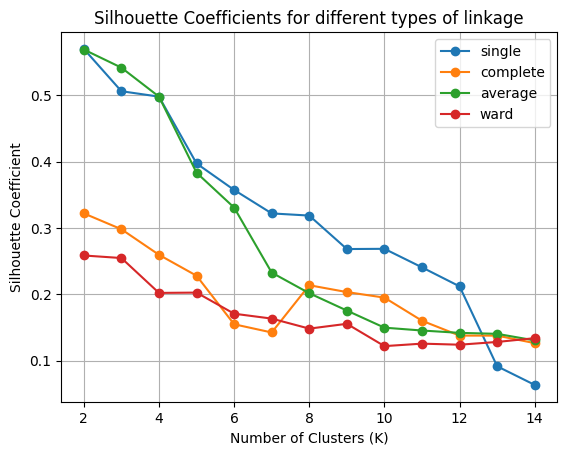

In [18]:
K = range(2, 15)
linktype = ["single", "complete", "average", "ward"]

plt.figure()
for link in linktype:
    scores = []
    for k in K:
        labels_agglomerative = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_scaled)
        scores.append(silhouette_score(X_scaled, labels_agglomerative))
    plt.plot(list(K), scores, "o-", label=link)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Coefficient")
plt.title("Silhouette Coefficients for different types of linkage")
plt.grid(True)
plt.legend()
plt.show()

From the plot, it is clear that the silhouette coefficient is maximized for K=2 for all types of linkage. As K increases, it decreases more or less steeply depending on the type of linkage.\
The choice **K=2** is to be preferred for this dataset.

# **8. Agglomerative clustering**

Clustering is repeated for each type of linkage.

**8.1 Agglomerative MIN**

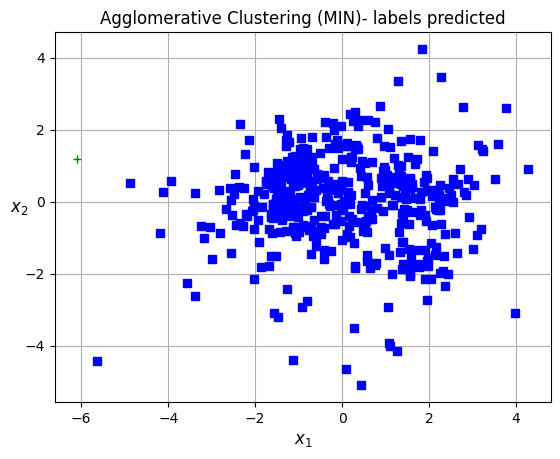


Cluster sizes:
0    439
1      1
Name: count, dtype: int64


In [19]:
# set clustering algorithm

# MIN
clustering = AgglomerativeClustering(n_clusters=2, linkage='single')

# train and predict from data
labels_min = clustering.fit_predict(X_scaled)

# plot predicted labels in the PCA-space (2-dimesional)
plot_dataset(X_pca, labels_min, title="Agglomerative Clustering (MIN)- labels predicted")

#clusters sizes
print("\nCluster sizes:")
print(pd.Series(labels_min).value_counts().sort_index())

**8.2 Agglomerative MAX**

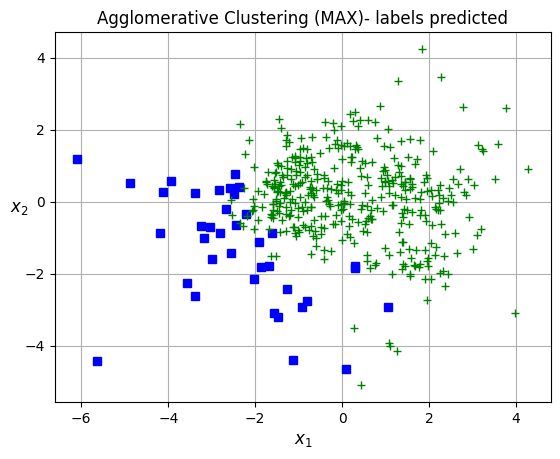


Cluster sizes:
0     38
1    402
Name: count, dtype: int64


In [20]:
# set clustering algorithm

# MAX
clustering = AgglomerativeClustering(n_clusters=2, linkage='complete')

# train and predict from data
labels_max = clustering.fit_predict(X_scaled)


# plot predicted labels in the PCA-space (2-dimesional)
plot_dataset(X_pca, labels_max, title="Agglomerative Clustering (MAX)- labels predicted")

#clusters sizes
print("\nCluster sizes:")
print(pd.Series(labels_max).value_counts().sort_index())

**8.3 Agglomerative Group-Average**

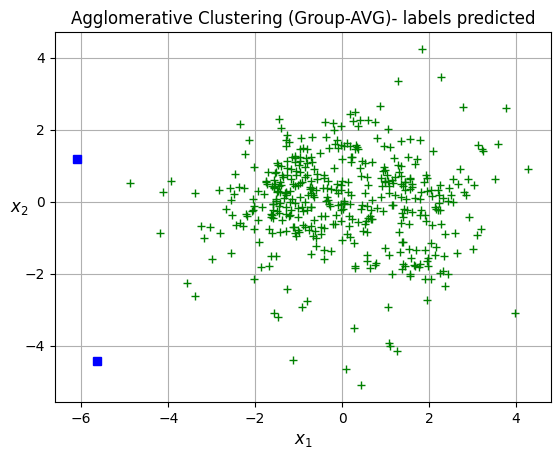


Cluster sizes:
0      2
1    438
Name: count, dtype: int64


In [21]:
# set clustering algorithm

# Group-Average
clustering = AgglomerativeClustering(n_clusters=2, linkage='average')

# train and predict from data
labels_avg = clustering.fit_predict(X_scaled)

# plot predicted labels in the PCA-space (2-dimesional)
plot_dataset(X_pca, labels_avg, title="Agglomerative Clustering (Group-AVG)- labels predicted")

#clusters sizes
print("\nCluster sizes:")
print(pd.Series(labels_avg).value_counts().sort_index())

**8.4 Agglomerative Ward's Method**

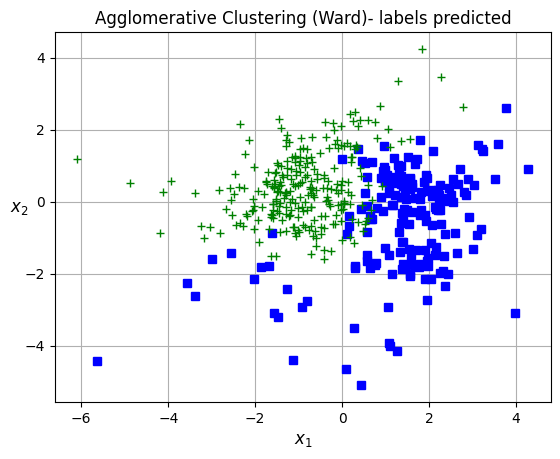


Cluster sizes:
0    178
1    262
Name: count, dtype: int64


In [22]:
# set clustering algorithm

# Ward's Method
clustering = AgglomerativeClustering(n_clusters=2, linkage='ward')

# train and predict from data
labels_ward = clustering.fit_predict(X_scaled)

# plot predicted labels in the PCA-space (2-dimesional)
plot_dataset(X_pca, labels_ward, title="Agglomerative Clustering (Ward)- labels predicted")

#clusters sizes
print("\nCluster sizes:")
print(pd.Series(labels_ward).value_counts().sort_index())

**8.5 Comment on linkage**

The most balanced result in terms of cluster size is given by **Ward's Method** linkage, yielding two clusters of size 178 and 262, whereas the other linkage methods encourage the creation of a huge cluster with respect to the other, especially MIN and Group-Average.\
Hence, Ward's Method is the preferred linkage method for this dataset.

**8.6 Dendogram**

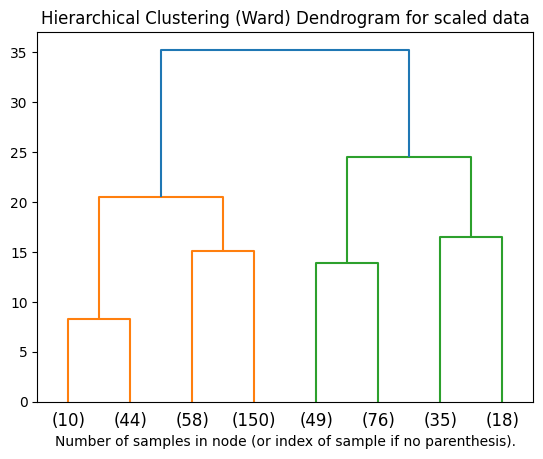

In [23]:
shc.dendrogram(shc.linkage(X_scaled, method='ward'), truncate_mode='level', p=2)
plt.title("Hierarchical Clustering (Ward) Dendrogram for scaled data")
plt.xlabel("Number of samples in node (or index of sample if no parenthesis).")
plt.show()

# **9. DBSCAN**

**9.1 Choice of Eps and MinPts**

For the choice of DBSCAN hyperparameters it is a safe choice to rely on standard heuristics and rules of thumb. Specifically:
- To choose MinPts, a common rule of thumb is to set it equal to two times the dimensionality of the data (number of numerical features in this case), i.e. **MinPts**=2*6=**12**.
- To choose Eps, the standard heuristics suggests to plot the sorted distance of every sample to its MinPts-th nearest neighbour and decide Eps based on sharp change (**Eps=1.5**).

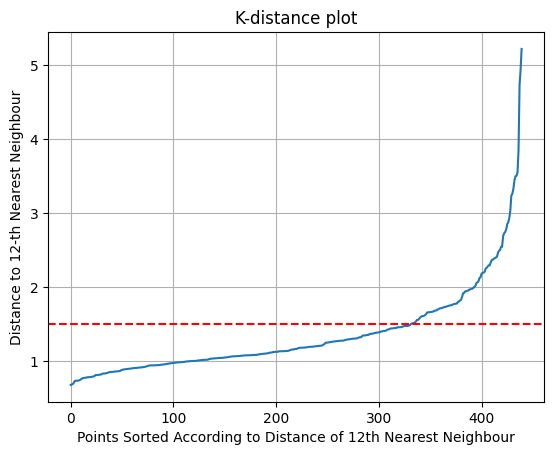

In [24]:
min_samples = 12

neigh = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = neigh.kneighbors(X_scaled)

k_dist = np.sort(distances[:, -1])

plt.figure()
plt.plot(k_dist)
plt.title(f"K-distance plot")
plt.xlabel("Points Sorted According to Distance of 12th Nearest Neighbour")
plt.ylabel(f"Distance to 12-th Nearest Neighbour")
plt.axhline(y=1.5, color='r',linestyle='--')
plt.grid(True)
plt.show()

**9.2 Apply DBSCAN**

In [25]:
# set clustering algorithm
dbscan = DBSCAN(eps=1.5, min_samples=10)

# train and predict from data
labels_dbscan = dbscan.fit_predict(X_scaled)


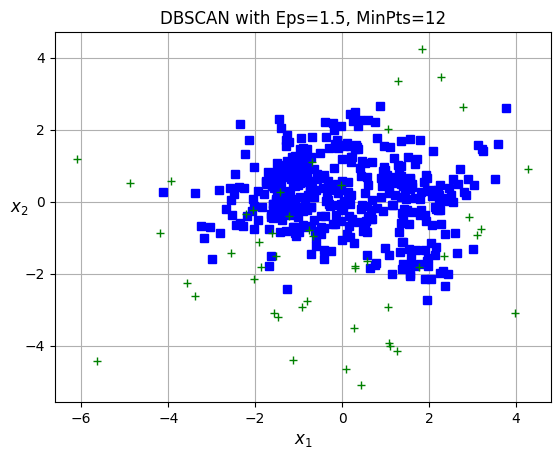

Number of noise points: 48
Number of clusters: 1

Cluster sizes:
0    392
Name: count, dtype: int64


In [26]:

#noise points
n_noise = int(np.sum(labels_dbscan == -1))

#number of clusters excluding noise
n_clusters= int(len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))

# plot predicted labels in the PCA-space (2-dimesional)
plot_dataset(X_pca, labels_dbscan, title=f"DBSCAN with Eps=1.5, MinPts=12")

print("Number of noise points:", n_noise)
print("Number of clusters:", n_clusters)

#clusters sizes
print("\nCluster sizes:")
print(pd.Series(labels_dbscan[labels_dbscan != -1]).value_counts().sort_index())



DBSCAN groups the samples into **one big cluster** of size **392**.\
**48** samples have been labeled as **noise points** and hence have not been assigned to any cluster, following the logic of this density-based algorithm.

## **10. Evaluation of clustering performances**

**10.1 External metrics**

The best way to evaluate the performances of a clustering algorithm is to compare the results of the prediction with *ground truth labels*, that categorize samples into groups based on assignment by a human.\
Here there are no *ground truth labels*, however, external metrics  can be computed in order to compare each algorithm's discovered clusters against the categorical features that were excluded from the task, i.e. *Channel* and *Region*.\
The most employed external metrics are:
- **Adjusted Rand Index** (ARI)
- **Normalized Mutual Information** (NMI)\



In [27]:
def external_metrics(true_labels, predicted_labels):
    ari = adjusted_rand_score(true_labels, predicted_labels)
    nmi = normalized_mutual_info_score(true_labels, predicted_labels, average_method="arithmetic")
    return ari, nmi

rows = []
channel = data["Channel"].astype(int).to_numpy()
region  = data["Region"].astype(int).to_numpy()
for algo_name, pred_labels in [
    ("K-Means", labels_kmeans),
    ("Agglomerative (Ward)", labels_ward),
    ("DBSCAN", labels_dbscan),
]:
    ari_channel, nmi_channel = external_metrics(channel, pred_labels)
    ari_region, nmi_region = external_metrics(region, pred_labels)
    rows.append({
        "Algorithm": algo_name,
        "ARI vs Channel": ari_channel,
        "NMI vs Channel": nmi_channel,
        "ARI vs Region": ari_region,
        "NMI vs Region": nmi_region,
    })

external_df = pd.DataFrame(rows).set_index("Algorithm")
external_df.style.background_gradient(cmap="Blues")

,ARI vs Channel,NMI vs Channel,ARI vs Region,NMI vs Region
Algorithm,,,,
K-Means,0.513543,0.445425,-0.007655,0.001923
Agglomerative (Ward),0.539236,0.447423,-0.007753,0.002767
DBSCAN,-0.018821,0.003168,-0.046951,0.007818


The most significant results come from K-Means and Agglomerative (Ward), which makes sense since DBSCAN finds only one big cluster, whereas the other two algorithms find more balanced clusters in terms of size.

In general, clusters are **more in line (higher ARI and NMI) with *Channel*** rather than *Region*.

This makes a lot of sense since samples with different channels (Hotel/Restaurant/Cafè vs Retail) tend to have different purchasing behaviour, while customers of the same channel but in different regions tend to have similar spending behaviour.

**NB**: low values for these metrics do not necessarily imply that the clustering is bad. As it has been said, they are used to compare clusters wrt *Channel* and *Region*, hence a low value indicates that the customer segmentation based on spending behaviour (carried out by the clustering) is not in line with *Channel* and *Region*, which is possible (e.g. two customers in different regions could have very similar spending behaviour).

**10.2 Internal metrics**

**10.2.1 Silhoette Coefficients**

In [28]:
# Drop noise points before computing silhouette coefficient for DBSCAN
# with only one cluster, silhouette coefficient cannot be computed
# as there is only one cluster and sil_dbscan could directly be set to 'not defined'
# but for the sake of completeness the following code is included

if n_clusters >= 2:
    mask = labels_dbscan != -1
    sil_dbscan = silhouette_score(X_scaled[mask], labels_dbscan[mask])
else:
    sil_dbscan = np.nan


sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
sil_ward = silhouette_score(X_scaled, labels_ward)

summary_rows = [
    {"Algorithm": "K-Means", "n_clusters_found": 2, "Silhouette": sil_kmeans},
    {"Algorithm": "Agglomerative (Ward)", "n_clusters_found": 2, "Silhouette": sil_ward},
    {"Algorithm": "DBSCAN", "n_clusters_found": 1, "Silhouette": sil_dbscan},
]
summary_df = pd.DataFrame(summary_rows).set_index("Algorithm")
summary_df.style.background_gradient(subset=["Silhouette"], cmap="Greens")


,n_clusters_found,Silhouette
Algorithm,,
K-Means,2,0.290328
Agglomerative (Ward),2,0.258495
DBSCAN,1,nan


The highest silhouette coefficient is achieved by **K-Means**, meaning that it is the best of the three in terms of separation of clusters.\
However, its value (**0.29**) is far from optimal, since good values of this coefficient should be closer to 1.\
Note that the coefficient is **not defined for DBSCAN**, since the latter finds one big cluster and hence it does not make sense to talk about cluster separation in this case.

**10.2.2 Clustering Matrix**

In [29]:
# helper function that sorts some data given the cluster labels
def sort_data(data, cluster_labels):
    sorting_indexes = np.argsort(cluster_labels)
    sorted_data = data[sorting_indexes]
    return sorted_data

def get_clustering_matrix(data, model):
    #fit model on data
    cluster_labels = model.fit_predict(data)
    # sort data accordingly to cluster labels
    sorted_data = sort_data(data, cluster_labels)
    # calculate distances between samples
    distance_matrix = pairwise_distances(sorted_data)
    return distance_matrix

# plot a distance matrix
def plot_clustering_matrix(data, model, title=""):
    distance_matrix = get_clustering_matrix(data, model)
    figure, axes = plt.subplots()
    image = axes.imshow(distance_matrix, cmap='jet_r')
    figure.colorbar(image)
    plt.title(title)
    plt.show()
    return

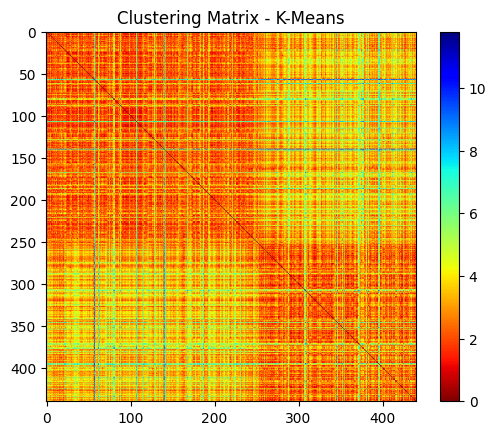

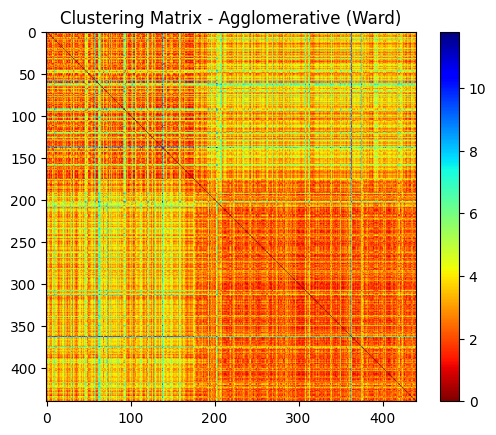

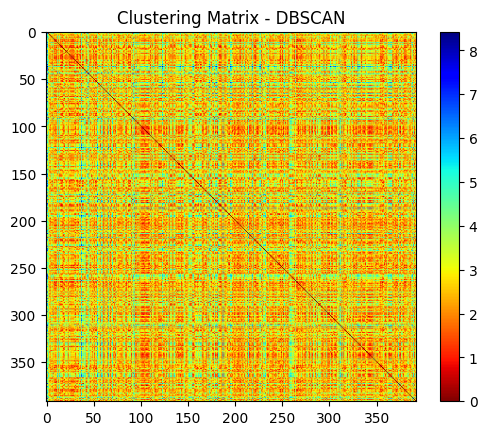

In [30]:
#for DBSCAN, noise points must be dropped

algos = [
    (KMeans(n_clusters=2, random_state=0, n_init=10), "K-Means"),
    (AgglomerativeClustering(n_clusters=2, linkage='ward'), "Agglomerative (Ward)")
]

for model , title in algos:
    plot_clustering_matrix(X_scaled, model, title=f"Clustering Matrix - {title}")

algo = [(DBSCAN(eps=1.5, min_samples=12), "DBSCAN")]
mask = labels_dbscan != -1

for model , title in algo:
    plot_clustering_matrix(X_scaled[mask], model, title=f"Clustering Matrix - {title}")



In line with the results of the silhouette coefficients, it can be seen that the clustering matrix of **K-Means** is the one that shows strongest block structure among the three methods, even though cluster separation is not optimally defined.\
The most messy clustering matrix is that of DBSCAN, in line with the observations made before.